In [53]:
import numpy as np
import tensorflow as tf
import kagglehub
from pathlib import Path
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import load_img, img_to_array
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2
import matplotlib.pyplot as plt
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score


path = Path(kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia"))
base_dir = path / "chest_xray" / "chest_xray"
train_directory, test_directory = base_dir / "train", base_dir / "test"

IMG, BATCH, SEED = (224, 224), 32, 42
AUTOTUNE = tf.data.AUTOTUNE
CLASS_NAMES = ["NORMAL", "PNEUMONIA"]            # NORMAL = 0, PNEUMONIA = 1
EXT = (".jpeg", ".jpg", ".png")

def list_files(directory):
    paths, labels = [], []
    for label, cls in enumerate(CLASS_NAMES):
        files = sorted(p for p in (directory / cls).iterdir() if p.suffix.lower() in EXT)
        paths += files
        labels += [label] * len(files)
    return paths, np.array(labels, dtype="float32")

all_paths, all_labels = list_files(train_directory)
test_paths, test_labels = list_files(test_directory)

train_paths, val_paths, train_labels, val_labels = train_test_split(
    all_paths, all_labels, test_size=0.15, stratify=all_labels, random_state=SEED)

n0, n1 = (train_labels == 0).sum(), (train_labels == 1).sum()
class_weights = {0: (n0 + n1) / (2 * n0), 1: (n0 + n1) / (2 * n1)}
print(len(train_paths), len(val_paths), len(test_paths), class_weights)

4433 783 624 {0: 1.9442982456140352, 1: 0.6730944427573641}


In [54]:
from tensorflow.keras.utils import load_img, img_to_array
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

def prepare_one(path, batch_axis=True):
    img = load_img(path, target_size=IMG, color_mode="rgb", interpolation="bilinear")
    x = img_to_array(img)             
    x = preprocess_input(x)            
    return np.expand_dims(x, axis=0) if batch_axis else x   

In [55]:
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import kagglehub
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input





In [56]:
path = Path(kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia"))
base_dir = path / "chest_xray" / "chest_xray"
train_directory = base_dir / "train"
test_directory  = base_dir / "test"

print(train_directory.exists(), test_directory.exists())

EXT = (".jpeg", ".jpg", ".png")
for split in ("train", "test"):
    for cls in ("NORMAL", "PNEUMONIA"):
        n = len([p for p in (base_dir / split / cls).iterdir() if p.suffix.lower() in EXT])
        print(f"{split:5s} {cls:10s} {n}")

True True
train NORMAL     1341
train PNEUMONIA  3875
test  NORMAL     234
test  PNEUMONIA  390


In [57]:
IMG, BATCH, SEED = (224, 224), 32, 42
AUTOTUNE = tf.data.AUTOTUNE
CLASS_NAMES = ["NORMAL", "PNEUMONIA"]

In [58]:
common = dict(
    labels="inferred",
    label_mode="binary",
    class_names=CLASS_NAMES,
    color_mode="rgb",
    batch_size=BATCH,
    image_size=IMG,
    interpolation="bilinear",
    seed=SEED,
)

train_ds, val_ds = tf.keras.utils.image_dataset_from_directory(
    train_directory, validation_split=0.15, subset="both", shuffle=True, **common)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_directory, shuffle=False, **common)

class_names = train_ds.class_names
print(class_names)

Found 5216 files belonging to 2 classes.
Using 4434 files for training.
Using 782 files for validation.
Found 624 files belonging to 2 classes.
['NORMAL', 'PNEUMONIA']


In [59]:
images, labels = next(iter(train_ds))
print("images:", images.shape, "rank", images.shape.rank, images.dtype)
print("labels:", labels.shape, np.unique(labels.numpy()))
print("pixel range:", images.numpy().min(), images.numpy().max())

images: (32, 224, 224, 3) rank 4 <dtype: 'float32'>
labels: (32, 1) [0. 1.]
pixel range: 0.0 255.0


NORMAL=1341 PNEUMONIA=3875 weights={0: 1.9448173005219984, 1: 0.6730322580645162}


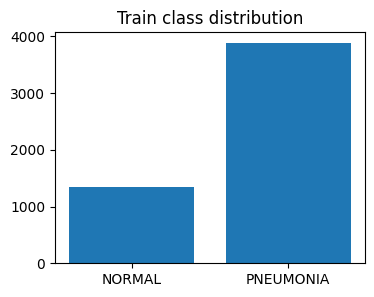

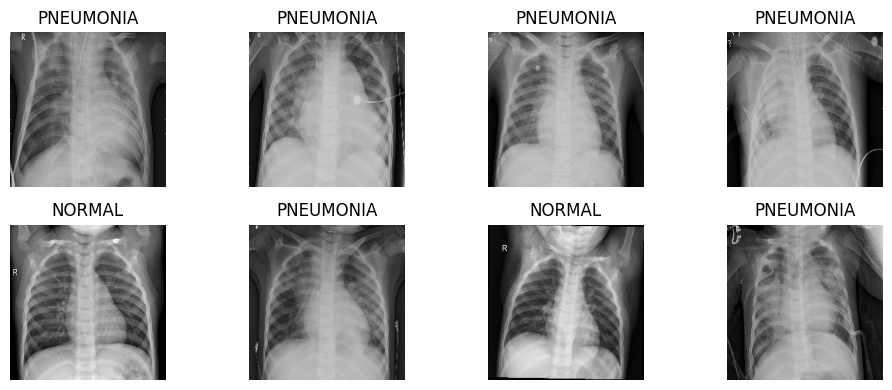

In [60]:
n_normal = len(list((train_directory / "NORMAL").glob("*.jpeg")))
n_pneu   = len(list((train_directory / "PNEUMONIA").glob("*.jpeg")))
total = n_normal + n_pneu
class_weights = {0: total / (2 * n_normal), 1: total / (2 * n_pneu)}
print(f"NORMAL={n_normal} PNEUMONIA={n_pneu} weights={class_weights}")

plt.figure(figsize=(4, 3))
plt.bar(class_names, [n_normal, n_pneu])
plt.title("Train class distribution")
plt.show()

plt.figure(figsize=(10, 4))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[int(labels[i][0])])
    plt.axis("off")
plt.tight_layout()
plt.show()

###MobileNetV2 preprocessing

In [75]:
def prep(x, y):
    return preprocess_input(x), y
  ## 0-255 => [-1 1]

### builder model (freze cnn)
feature extracting


In [76]:

base = MobileNetV2(
    weights="imagenet", include_top=False, input_shape=(224, 224, 3),
)
base.trainable = False                      


### classification avec Normal 0 et Pnomia 1

In [77]:
from tensorflow import keras

inputs = keras.Input(shape=(224, 224, 3))
x = base(inputs, training=False)            
x = layers.GlobalAveragePooling2D()(x)      
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
tl_model = keras.Model(inputs, outputs, name="mobilenetv2_tl")

### creer function pour evaluer

In [78]:
def make_metrics():                         
    return [keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc")]

In [79]:
tl_model.compile(optimizer=keras.optimizers.Adam(),
                 loss="binary_crossentropy", metrics=make_metrics())

tl_model.summary()
n_train = sum(int(w.numpy().size) for w in tl_model.trainable_weights)
n_frozen = sum(int(w.numpy().size) for w in tl_model.non_trainable_weights)
print(f"Trainable: {n_train:,} | Non-trainable: {n_frozen:,}") 

Model: "mobilenetv2_tl"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_12 (InputLayer)       [(None, 224, 224, 3)]     0         
                                                                 
 mobilenetv2_1.00_224 (Func  (None, 7, 7, 1280)        2257984   
 tional)                                                         
                                                                 
 global_average_pooling2d_5  (None, 1280)              0         
  (GlobalAveragePooling2D)                                       
                                                                 
 dropout_5 (Dropout)         (None, 1280)              0         
                                                                 
 dense_5 (Dense)             (None, 1)                 1281      
                                                                 
Total params: 2259265 (8.62 MB)
Trainable params: 12

In [67]:
train_ds

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 1), dtype=tf.float32, name=None))>

## Entrainer le model

In [80]:
early_stop = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

history = tl_model.fit(
    train_ds,validation_data=val_ds,epochs=10,class_weight=class_weights,callbacks=[early_stop],
)

Epoch 1/10


2026-10-21 11:39:15.674218: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:454] Loaded cuDNN version 8907
2026-10-21 11:39:19.171903: I external/local_xla/xla/service/service.cc:168] XLA service 0x7f0250563bb0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-10-21 11:39:19.171990: I external/local_xla/xla/service/service.cc:176]   StreamExecutor device (0): Tesla V100-PCIE-16GB, Compute Capability 7.0
2026-10-21 11:39:19.172009: I external/local_xla/xla/service/service.cc:176]   StreamExecutor device (1): Tesla V100-PCIE-16GB, Compute Capability 7.0
2026-10-21 11:39:19.180272: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792582759.290019    2676 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


139/139 [==============================] - 13s 50ms/step - loss: 0.4448 - accuracy: 0.7905 - precision: 0.9198 - recall: 0.7856 - auc: 0.8741 - val_loss: 0.3152 - val_accuracy: 0.8683 - val_precision: 0.9657 - val_recall: 0.8564 - val_auc: 0.9463
Epoch 2/10
139/139 [==============================] - 5s 37ms/step - loss: 0.2770 - accuracy: 0.8843 - precision: 0.9695 - recall: 0.8712 - auc: 0.9509 - val_loss: 0.2852 - val_accuracy: 0.8760 - val_precision: 0.9714 - val_recall: 0.8615 - val_auc: 0.9589
Epoch 3/10
139/139 [==============================] - 6s 42ms/step - loss: 0.2384 - accuracy: 0.8974 - precision: 0.9745 - recall: 0.8846 - auc: 0.9639 - val_loss: 0.2410 - val_accuracy: 0.8900 - val_precision: 0.9703 - val_recall: 0.8818 - val_auc: 0.9650
Epoch 4/10
139/139 [==============================] - 5s 33ms/step - loss: 0.2277 - accuracy: 0.9008 - precision: 0.9727 - recall: 0.8910 - auc: 0.9674 - val_loss: 0.2287 - val_accuracy: 0.8990 - val_precision: 0.9724 - val_recall: 0.8919 

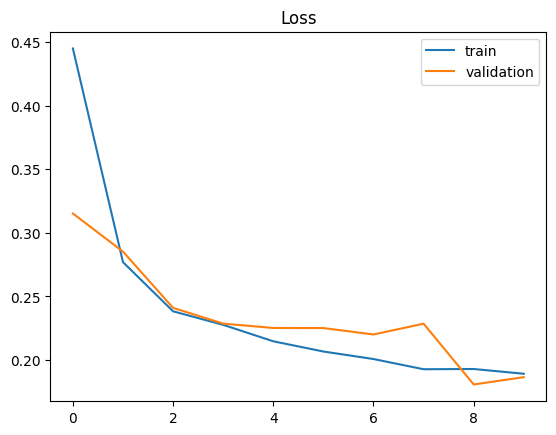

In [81]:
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.legend()
plt.title("Loss")
plt.show()

In [82]:
y_true = np.concatenate([y.numpy() for _, y in test_ds]).ravel()   
proba  = tl_model.predict(test_ds).ravel()                     
y_pred = (proba >= 0.5).astype(int)                                

print(confusion_matrix(y_true, y_pred))
print(classification_report(y_true, y_pred, target_names=["NORMAL", "PNEUMONIA"]))

20/20 [==============================] - 2s 43ms/step
[[133 101]
 [ 20 370]]
              precision    recall  f1-score   support

      NORMAL       0.87      0.57      0.69       234
   PNEUMONIA       0.79      0.95      0.86       390

    accuracy                           0.81       624
   macro avg       0.83      0.76      0.77       624
weighted avg       0.82      0.81      0.79       624



## Ruc , Auc

In [83]:
print("ROC-AUC:", roc_auc_score(y_true, proba))

ROC-AUC: 0.9229454306377383
